# 04 — Двухэтапная рекомендательная система с CatBoostRanker

В ноутбуке проверяется, улучшает ли обучение ранжированию рекомендации топ-10 по сравнению с существующими моделями коллаборативной фильтрации. Все метрики рассчитаны на временных выборках Retailrocket; результаты заранее не предполагаются.

## 1. Постановка задачи

Для каждого пользователя нужно рекомендовать до десяти ещё не просмотренных товаров, с которыми он, вероятно, взаимодействует в следующем временном интервале. Используем бинарную релевантность: любой будущий просмотр, переход в корзину или заказ получает метку 1. Метка 0 означает только, что взаимодействие не было замечено в целевом интервале.

Основная метрика — макроусреднённая NDCG@10. Recall@10, Precision@10, покрытие каталога Coverage@10 и Recall@100 кандидатов показывают дополнительные стороны качества. Тестовый период не используется до фиксации всех решений по модели.

## 2. Архитектура рекомендательной системы из двух этапов

```mermaid
flowchart LR
  H[История взаимодействий] --> A[Кандидаты от implicit ALS]
  H --> K[Кандидаты от ItemKNN]
  A --> U[Объединение и удаление повторов, до 100 от каждой модели]
  K --> U
  U --> F[Признаки пользователя, товара и кандидата на момент среза]
  F --> R[CatBoostRanker]
  R --> T[Топ-10 ещё не просмотренных товаров]
```

Ранжировщик может переставлять только товары, найденные генераторами. Поэтому полнота кандидатов задаёт верхнюю границу полноты всей системы. ALS — готовая библиотечная реализация из `implicit`; в этом ноутбуке в проекте используется готовая реализация из `implicit`.

## Временной протокол и воспроизводимый эксперимент

Исходное хронологическое разбиение 70/15/15 не меняется. Для обучения ранжировщика внутри обучающего интервала выделяется дополнительный срез по уникальным временным отметкам: первые 80% составляют доступную историю, последние 20% — целевой интервал. Модели-кандидатогенераторы и признаки для этого среза используют только предшествующую историю. Для проверочной выборки кандидаты и признаки строятся только по обучающей; для тестовой — по обучающей и проверочной. Когорта и каталог из 1 500 товаров выбираются только по обучающей выборке. Будущие ID товаров используются только для формирования целевых меток после генерации кандидатов.

In [1]:
from pathlib import Path
import json
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
import catboost

ROOT = Path.cwd()
if not (ROOT / "src").is_dir():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
PROCESSED = ROOT / "data" / "processed"
FIGURES = ROOT / "outputs" / "figures"
METRICS = ROOT / "outputs" / "metrics"
MODELS = ROOT / "outputs" / "models"
for folder in (FIGURES, METRICS, MODELS):
    folder.mkdir(parents=True, exist_ok=True)

from src.candidate_generation import (
    candidate_recall_at_100,
    generate_candidate_frame,
)
from src.evaluation import evaluate_recommender
from src.ranker import (
    CandidateRankerRecommender,
    CATEGORICAL_FEATURES,
    DEFAULT_RANKER_PARAMS,
    RANKER_FEATURES,
    feature_importance_frame,
    fit_catboost_ranker,
    make_ranker_pool,
)
from src.ranking_features import (
    attach_binary_targets,
    build_ranking_features,
    split_history_target,
)
from src.recommendation import (
    ImplicitLibraryALSRecommender,
    ItemKNNRecommender,
    PopularityRecommender,
    RecentPopularityRecommender,
    build_interaction_data,
    select_benchmark_users,
    select_catalog_items,
)
from src.retailrocket import load_processed_events

SEED = 42
MAX_USERS = 20000
MAX_ITEMS = 1500
CANDIDATES_PER_MODEL = 100
K = 10

train = load_processed_events(PROCESSED / "train.csv")
validation = load_processed_events(PROCESSED / "validation.csv")
cohort = select_benchmark_users(train, min_history=5, max_users=MAX_USERS,
                                random_state=SEED)
catalog = select_catalog_items(train, max_items=MAX_ITEMS)
train_benchmark = train[
    train.visitorid.isin(cohort) & train.itemid.isin(catalog)
].copy()
validation_benchmark = validation[
    validation.visitorid.isin(cohort) & validation.itemid.isin(catalog)
].copy()

assert train.event_time.max() < validation.event_time.min()
print("Версия CatBoost:", catboost.__version__)
with (METRICS / "selected_model_params.json").open() as file:
    selected_parameters = json.load(file)
itemknn_params = selected_parameters["itemknn"]["parameters"]
als_params = selected_parameters["implicit_als"]["parameters"]

print("Бенчмарк: {:,} пользователей и {:,} товаров, отобранных по обучающей выборке.".format(
    len(cohort), len(catalog)))

/Users/mariatreseva/opt/anaconda3/lib/python3.9/site-packages/pandas/core/computation/expressions.py:21: UserWarning: Pandas requires version '2.8.4' or newer of 'numexpr' (version '2.8.1' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED
/Users/mariatreseva/opt/anaconda3/lib/python3.9/site-packages/pandas/core/arrays/masked.py:61: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.4' currently installed).
  from pandas.core import (


Версия CatBoost: 1.2.7
Бенчмарк: 20,000 пользователей и 1,500 товаров, отобранных по обучающей выборке.


## 3. Генерация кандидатов — обучающий срез

Обе модели обучаются только на ранней части истории внутри обучающей выборки. Для каждого пользователя объединяются до 100 ещё не просмотренных товаров от каждой модели, повторы удаляются. Если товар предложен только одной моделью, у второй модели остаются пропущенные оценки и ранги, а также явный признак источника; пропуски не подменяются настоящим нулевым баллом.

In [2]:
rank_history, rank_target, rank_cutoff = split_history_target(
    train, history_fraction=0.8
)
rank_user_counts = rank_history.groupby("visitorid").size()
rank_users = sorted(int(user_id) for user_id in
                    rank_user_counts[rank_user_counts >= 5].index)
rank_catalog = select_catalog_items(rank_history, max_items=MAX_ITEMS)
rank_target_benchmark = rank_target[
    rank_target.visitorid.isin(rank_users)
    & rank_target.itemid.isin(rank_catalog)
].copy()
rank_candidate_users = sorted(
    rank_target_benchmark.visitorid.astype(int).unique()
)
assert rank_history.event_time.max() < rank_cutoff
assert rank_target.event_time.min() >= rank_cutoff
assert rank_target.event_time.max() < validation.event_time.min()

rank_data = build_interaction_data(
    rank_history, user_ids=rank_users, item_ids=rank_catalog
)
rank_als = ImplicitLibraryALSRecommender(**als_params).fit(rank_data)
rank_itemknn = ItemKNNRecommender(**itemknn_params).fit(rank_data)
rank_candidates = generate_candidate_frame(
    rank_candidate_users, rank_history, rank_als, rank_itemknn,
    candidates_per_model=CANDIDATES_PER_MODEL,
)
rank_features = build_ranking_features(
    rank_history, rank_candidates, rank_cutoff, snapshot_id="rank_train"
)
rank_training = attach_binary_targets(
    rank_features, rank_target_benchmark, rank_cutoff
)
print("Граница обучающего среза:", rank_cutoff)
print("Строк-кандидатов:", len(rank_training),
      "| положительных пар-кандидатов:", int(rank_training.target.sum()),
      "| пользователей хотя бы с одним положительным кандидатом:",
      int(rank_training.groupby("user_id").target.max().sum()))
display(rank_training[["als_score", "als_rank", "has_als",
                       "itemknn_score", "itemknn_rank", "has_itemknn",
                       "candidate_source", "target"]].head().rename(columns={
                           "als_score": "Оценка ALS", "als_rank": "Ранг ALS",
                           "has_als": "Есть в ALS", "itemknn_score": "Оценка ItemKNN",
                           "itemknn_rank": "Ранг ItemKNN", "has_itemknn": "Есть в ItemKNN",
                           "candidate_source": "Источник кандидата", "target": "Целевая метка",
                       }).replace({"Источник кандидата": {
                           "both": "Обе модели", "als_only": "Только ALS",
                           "itemknn_only": "Только ItemKNN",
                       }}))

/Users/mariatreseva/opt/anaconda3/lib/python3.9/site-packages/scipy/sparse/_index.py:146: SparseEfficiencyWarning: Changing the sparsity structure of a csr_matrix is expensive. lil_matrix is more efficient.
  self._set_arrayXarray(i, j, x)


Граница обучающего среза: 2015-07-16 13:34:50.605000+00:00
Строк-кандидатов: 160284 | положительных пар-кандидатов: 566 | пользователей хотя бы с одним положительным кандидатом: 285


,Оценка ALS,Ранг ALS,Есть в ALS,Оценка ItemKNN,Ранг ItemKNN,Есть в ItemKNN,Источник кандидата,Целевая метка
0,0.930127,1.0,True,3.907325,1.0,True,Обе модели,0
1,0.552338,2.0,True,3.263422,2.0,True,Обе модели,0
2,0.539608,3.0,True,2.806326,5.0,True,Обе модели,0
3,0.505025,4.0,True,2.871681,3.0,True,Обе модели,0
4,0.496123,5.0,True,2.871344,4.0,True,Обе модели,0


## 4. Формирование признаков

Для каждого кандидата рассчитываются оценки и ранги моделей-источников, а также признаки наличия кандидата в их списках. Признаки пользователя включают число событий каждого типа, число уникальных товаров в истории и часы с последней активности. Признаки товара включают число событий каждого типа, число уникальных пользователей и количество событий за предыдущие семь дней. Функция построения признаков отклоняет историю с событиями во время среза или после него, поэтому будущие взаимодействия не попадут в агрегаты.

In [3]:
feature_columns = RANKER_FEATURES
FEATURE_LABELS = {
    "als_score": "Оценка ALS", "als_rank": "Ранг ALS",
    "has_als": "Есть в ALS", "itemknn_score": "Оценка ItemKNN",
    "itemknn_rank": "Ранг ItemKNN", "has_itemknn": "Есть в ItemKNN",
    "candidate_source": "Источник кандидата",
    "user_view_count": "Просмотры пользователя",
    "user_addtocart_count": "Добавления в корзину пользователя",
    "user_transaction_count": "Покупки пользователя",
    "user_unique_items": "Уникальные товары в истории пользователя",
    "user_last_activity_hours": "Часы с последней активности пользователя",
    "user_total_events": "Всего событий пользователя",
    "item_view_count": "Просмотры товара",
    "item_addtocart_count": "Добавления товара в корзину",
    "item_transaction_count": "Покупки товара",
    "item_unique_users": "Уникальные пользователи товара",
    "item_event_count_7d": "События товара за 7 дней",
    "target": "Целевая метка",
}
feature_summary = rank_training[feature_columns + ["target"]].describe(include="all").T
feature_summary = feature_summary.rename(columns={
    "count": "Количество", "unique": "Уникальных значений",
    "top": "Самое частое", "freq": "Частота",
    "mean": "Среднее", "std": "Стандартное отклонение",
    "min": "Минимум", "max": "Максимум",
    "25%": "25-й процентиль", "50%": "Медиана", "75%": "75-й процентиль",
})
feature_summary.index = feature_summary.index.map(
    lambda feature: FEATURE_LABELS.get(feature, feature)
)
display(feature_summary)

,Количество,Уникальных значений,Самое частое,Частота,Среднее,Стандартное отклонение,Минимум,25-й процентиль,Медиана,75-й процентиль,Максимум
Оценка ALS,92200.0,NaN,NaN,NaN,0.172791,0.169157,0.0,0.067111,0.134461,0.221144,1.663052
Ранг ALS,92200.0,NaN,NaN,NaN,50.5,28.866227,1.0,25.75,50.5,75.25,100.0
Есть в ALS,160284,2,True,92200,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Оценка ItemKNN,92200.0,NaN,NaN,NaN,0.351819,1.172303,0.0,0.0,0.059898,0.248231,49.473633
Ранг ItemKNN,92200.0,NaN,NaN,NaN,50.5,28.866227,1.0,25.75,50.5,75.25,100.0
Есть в ItemKNN,160284,2,True,92200,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Источник кандидата,160284,3,als_only,68084,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Просмотры пользователя,160284.0,NaN,NaN,NaN,43.213022,151.295923,2.0,6.0,10.0,22.0,2898.0
Добавления в корзину пользователя,160284.0,NaN,NaN,NaN,2.481845,13.792993,0.0,0.0,0.0,1.0,306.0
Покупки пользователя,160284.0,NaN,NaN,NaN,1.151088,9.839608,0.0,0.0,0.0,0.0,248.0


## 5. Формирование целевой переменной

Кандидат получает метку 1, если пара пользователь–товар встретилась в будущем целевом интервале, независимо от типа события; иначе метка равна 0. Повторные события одной пары остаются одной положительной меткой. Целевой интервал обучающего среза находится внутри исходной обучающей выборки. Метки проверочной и тестовой выборок присоединяются только после того, как кандидаты и признаки построены по доступной к тому моменту истории.

## 6. Обучение и небольшой поиск CatBoostRanker

Сравним три конфигурации с одинаковым seed, максимумом 500 итераций и ранней остановкой по NDCG@10 на проверочной выборке: исходную (глубина 6, шаг обучения 0,05), более неглубокую (глубина 4, 0,05) и с меньшим шагом (глубина 6, 0,03). Выбирается модель с полным набором признаков; два варианта ниже нужны для абляции на проверочной выборке.

**Гипотеза.** Уменьшение глубины 6→4 при шаге 0.05 снизит переобучение; уменьшение learning_rate 0.05→0.03 при глубине 6 позволит точнее оптимизировать порядок. Это два контролируемых сравнения с исходной точкой, а не полная сетка: взаимодействие глубины 4 с шагом 0.03 не проверяется. Ранняя остановка выбирает число деревьев на той же validation, поэтому результат подбора оптимистичен.

/Users/mariatreseva/opt/anaconda3/lib/python3.9/site-packages/scipy/sparse/_index.py:146: SparseEfficiencyWarning: Changing the sparsity structure of a csr_matrix is expensive. lil_matrix is more efficient.
  self._set_arrayXarray(i, j, x)


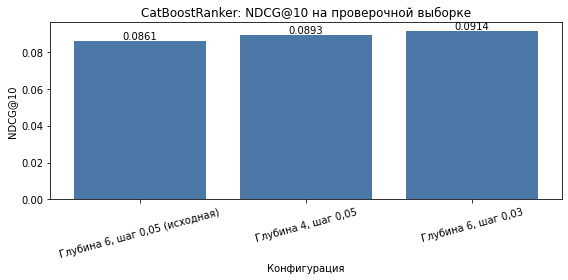

,Конфигурация,Глубина,Шаг обучения,Лучшая итерация,NDCG@10,Recall@10
0,"Глубина 6, шаг 0,05 (исходная)",6,0.05,22,0.0861,0.1192
1,"Глубина 4, шаг 0,05",4,0.05,70,0.0893,0.1208
2,"Глубина 6, шаг 0,03",6,0.03,62,0.0914,0.1214


Выбрана CatBoost-конфигурация по NDCG@10 на проверочной выборке: Глубина 6, шаг 0,03 — 0.0914


In [4]:
train_users_for_eval = sorted(validation_benchmark.visitorid.astype(int).unique())
validation_data = build_interaction_data(
    train_benchmark, user_ids=cohort, item_ids=catalog
)
validation_als = ImplicitLibraryALSRecommender(**als_params).fit(validation_data)
validation_itemknn = ItemKNNRecommender(**itemknn_params).fit(validation_data)
validation_candidates = generate_candidate_frame(
    train_users_for_eval, train_benchmark, validation_als, validation_itemknn,
    candidates_per_model=CANDIDATES_PER_MODEL,
)
validation_cutoff = validation.event_time.min()
validation_features = build_ranking_features(
    train, validation_candidates, validation_cutoff, snapshot_id="validation"
)
validation_rank_data = attach_binary_targets(
    validation_features, validation, validation_cutoff
)

catboost_search = [
    {"name": "Глубина 6, шаг 0,05 (исходная)", "depth": 6, "learning_rate": 0.05},
    {"name": "Глубина 4, шаг 0,05", "depth": 4, "learning_rate": 0.05},
    {"name": "Глубина 6, шаг 0,03", "depth": 6, "learning_rate": 0.03},
]
catboost_models = {}
catboost_rows = []
for config in catboost_search:
    params = dict(DEFAULT_RANKER_PARAMS)
    params.update({
        "depth": config["depth"],
        "learning_rate": config["learning_rate"],
        "allow_writing_files": False,
        "verbose": False,
        "thread_count": 4,
    })
    model = fit_catboost_ranker(
        rank_training, validation_rank_data, params=params,
        early_stopping_rounds=50,
    )
    catboost_models[config["name"]] = model
    validation_recommender = CandidateRankerRecommender(model, validation_features)
    metrics, _, _ = evaluate_recommender(
        validation_recommender, validation, train, cohort, catalog, k=K,
        relevance_mode="binary",
    )
    catboost_rows.append({
        **config,
        "best_iteration": int(model.get_best_iteration()),
        **metrics,
    })

catboost_tuning = pd.DataFrame(catboost_rows)
catboost_tuning.to_csv(METRICS / "ltr_catboost_tuning_validation.csv", index=False)
best_catboost_index = int(catboost_tuning["ndcg@10"].idxmax())
best_catboost_name = catboost_tuning.loc[best_catboost_index, "name"]
ranker = catboost_models[best_catboost_name]
best_iteration = ranker.get_best_iteration()
ranker_params = dict(DEFAULT_RANKER_PARAMS)
ranker_params.update({
    "depth": int(catboost_tuning.loc[best_catboost_index, "depth"]),
    "learning_rate": float(catboost_tuning.loc[best_catboost_index, "learning_rate"]),
    "allow_writing_files": False,
    "verbose": False,
    "thread_count": 4,
})

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(catboost_tuning["name"], catboost_tuning["ndcg@10"], color="#4C78A8")
ax.set(title="CatBoostRanker: NDCG@10 на проверочной выборке", ylabel="NDCG@10", xlabel="Конфигурация")
ax.tick_params(axis="x", labelrotation=15)
for position, value in enumerate(catboost_tuning["ndcg@10"]):
    ax.text(position, value, "{:.4f}".format(value), ha="center", va="bottom")
fig.tight_layout()
fig.savefig(FIGURES / "ltr_catboost_tuning_validation.png", dpi=180, bbox_inches="tight")
plt.show()
plt.close(fig)
catboost_tuning_display = catboost_tuning[["name", "depth", "learning_rate", "best_iteration", "ndcg@10", "recall@10"]].rename(columns={
    "name": "Конфигурация", "depth": "Глубина", "learning_rate": "Шаг обучения",
    "best_iteration": "Лучшая итерация", "ndcg@10": "NDCG@10", "recall@10": "Recall@10",
})
display(catboost_tuning_display.round(4))
print("Выбрана CatBoost-конфигурация по NDCG@10 на проверочной выборке:", best_catboost_name,
      "— {:.4f}".format(catboost_tuning.loc[best_catboost_index, "ndcg@10"]))



**Вывод по сохранённому прогону.** При шаге 0.05 глубина 4 лучше 6: NDCG@10 0.08933 против 0.08607 (+0.00326; 3.8%). При глубине 6 шаг 0.03 повышает NDCG до 0.09140 (+0.00533; 6.2%). Лучшие итерации — 22, 70 и 62 соответственно (индексы CatBoost с нуля): меньший шаг потребовал больше деревьев, а большая глубина сама по себе не дала выигрыша. Разница двух лучших вариантов 0.00206 (2.3%) невелика на 242 пользователях; это локальный выбор, а не доказанная победа глубокой модели. Precision лучшего NDCG-варианта ниже исходного (0.02107 против 0.02397), то есть улучшение порядка не означает больше попаданий в десятке.

## Абляция признаков

**Гипотеза.** Числовые оценки генераторов и признаки популярности/активности несут дополнительный сигнал поверх рангов и источника кандидатов. Удаляем каждую группу при неизменных кандидатах и выбранных depth/learning_rate. Число деревьев каждый раз выбирает early stopping; измеряем эффект всей процедуры обучения. Полный набор фиксирован заранее для test; абляция — диагностика.

,Вариант,Число признаков,Лучшая итерация,NDCG@10,Recall@10,Precision@10
0,Все признаки,18,62,0.0914,0.1214,0.0211
1,Без оценок ALS/ItemKNN,16,127,0.0846,0.1189,0.0219
2,Без популярности/активности,7,122,0.0773,0.1244,0.0207


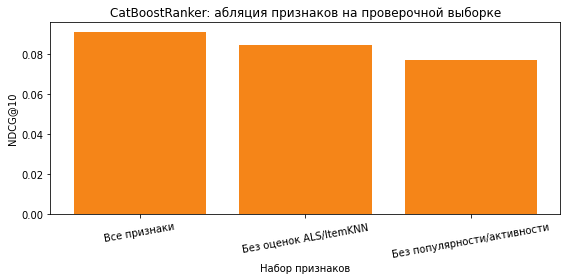

Абляция — диагностическое сравнение только на проверочной выборке; выбранная модель использует полный набор признаков.


In [5]:
cf_score_features = {"als_score", "itemknn_score"}
popularity_activity_features = {
    feature for feature in RANKER_FEATURES
    if feature.startswith(("user_", "item_"))
}
feature_variants = {
    "Все признаки": list(RANKER_FEATURES),
    "Без оценок ALS/ItemKNN": [
        feature for feature in RANKER_FEATURES if feature not in cf_score_features
    ],
    "Без популярности/активности": [
        feature for feature in RANKER_FEATURES
        if feature not in popularity_activity_features
    ],
}
ranker_ablation_models = {"Все признаки": ranker}
for variant_name, features in feature_variants.items():
    if variant_name == "Все признаки":
        continue
    categorical_features = [
        feature for feature in CATEGORICAL_FEATURES if feature in features
    ]
    ranker_ablation_models[variant_name] = fit_catboost_ranker(
        rank_training,
        validation_rank_data,
        params=ranker_params,
        early_stopping_rounds=50,
        feature_columns=features,
        categorical_features=categorical_features,
    )

ablation_rows = []
for variant_name, features in feature_variants.items():
    model = ranker_ablation_models[variant_name]
    recommender = CandidateRankerRecommender(
        model, validation_features, feature_columns=features
    )
    metrics, _, _ = evaluate_recommender(
        recommender, validation, train, cohort, catalog, k=K,
        relevance_mode="binary",
    )
    ablation_rows.append({
        "variant": variant_name,
        "feature_count": len(features),
        "best_iteration": int(model.get_best_iteration()),
        **metrics,
    })
ablation_results = pd.DataFrame(ablation_rows)
ablation_results.to_csv(METRICS / "ltr_ablation_validation.csv", index=False)
ablation_display = ablation_results[["variant", "feature_count", "best_iteration", "ndcg@10", "recall@10", "precision@10"]].rename(columns={
    "variant": "Вариант", "feature_count": "Число признаков",
    "best_iteration": "Лучшая итерация", "ndcg@10": "NDCG@10",
    "recall@10": "Recall@10", "precision@10": "Precision@10",
})
display(ablation_display.round(4))
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(ablation_results["variant"], ablation_results["ndcg@10"], color="#F58518")
ax.set(title="CatBoostRanker: абляция признаков на проверочной выборке", ylabel="NDCG@10", xlabel="Набор признаков")
ax.tick_params(axis="x", labelrotation=10)
fig.tight_layout()
fig.savefig(FIGURES / "ltr_feature_ablation_validation.png", dpi=180, bbox_inches="tight")
plt.show()
plt.close(fig)
print("Абляция — диагностическое сравнение только на проверочной выборке; выбранная модель использует полный набор признаков.")

**Вывод по сохранённому прогону.** Удаление оценок ALS/ItemKNN снижает NDCG 0.09140→0.08455 (−7.5%), удаление популярности/активности — до 0.07734 (−15.4%). Оба набора полезны в этой процедуре, особенно второй. Без популярности/активности Recall даже выше (0.12437 против 0.12138), а Coverage растёт с 42.9% до 53.9%: ранжировщик находит более широкий набор целей, но ставит их хуже. Абляция не доказывает причинность отдельных признаков; ранги генераторов сохраняются даже без их числовых оценок.

## 7. Сравнение систем на validation и закрытом test

**Гипотеза.** Ранжировщик улучшит порядок кандидатов относительно каждого генератора и сохранит преимущество на следующем временном интервале. Фиксируем параметры и полный набор признаков до чтения test. Validation в 04 использует binary relevance; значения graded NDCG из 02 не являются сопоставимым baseline. Test используется только для итогового измерения.

In [6]:
validation_ranker = CandidateRankerRecommender(ranker, validation_features)
validation_models = {
    "Global Popularity": PopularityRecommender().fit(
        train_benchmark, catalog_items=catalog
    ),
    "Recent Popularity (14d)": RecentPopularityRecommender().fit(
        train_benchmark, as_of=validation_cutoff, lookback_days=14,
        catalog_items=catalog
    ),
    "ItemKNN": validation_itemknn,
    "implicit ALS": validation_als,
    "CatBoostRanker (ALS + ItemKNN)": validation_ranker,
}
validation_summaries = []
validation_per_user = {}
for name, model in validation_models.items():
    summary, per_user, _ = evaluate_recommender(
        model, validation, train, cohort, catalog, k=K,
        relevance_mode="binary",
    )
    summary["model"] = name
    validation_summaries.append(summary)
    validation_per_user[name] = per_user
validation_results = pd.DataFrame(validation_summaries).set_index("model")
validation_results = validation_results.sort_values("ndcg@10", ascending=False)
validation_results.to_csv(METRICS / "ltr_validation_metrics.csv")
display(validation_results.rename_axis("Модель").round(4))

# Load the held-out period only after all model/configuration choices are fixed.
test = load_processed_events(PROCESSED / "test.csv")
assert validation.event_time.max() < test.event_time.min()
pretest_history = pd.concat([train, validation], ignore_index=True)
pretest_benchmark = pretest_history[
    pretest_history.visitorid.isin(cohort)
    & pretest_history.itemid.isin(catalog)
].copy()
test_benchmark = test[
    test.visitorid.isin(cohort) & test.itemid.isin(catalog)
].copy()
test_data = build_interaction_data(
    pretest_benchmark, user_ids=cohort, item_ids=catalog
)
test_als = ImplicitLibraryALSRecommender(**als_params).fit(test_data)
test_itemknn = ItemKNNRecommender(**itemknn_params).fit(test_data)
test_users_for_eval = sorted(test_benchmark.visitorid.astype(int).unique())
test_candidates = generate_candidate_frame(
    test_users_for_eval, pretest_benchmark, test_als, test_itemknn,
    candidates_per_model=CANDIDATES_PER_MODEL,
)
test_cutoff = test.event_time.min()
test_features = build_ranking_features(
    pretest_history, test_candidates, test_cutoff, snapshot_id="test"
)
test_ranker = CandidateRankerRecommender(ranker, test_features)
test_models = {
    "Global Popularity": PopularityRecommender().fit(
        pretest_benchmark, catalog_items=catalog
    ),
    "Recent Popularity (14d)": RecentPopularityRecommender().fit(
        pretest_benchmark, as_of=test_cutoff, lookback_days=14,
        catalog_items=catalog
    ),
    "ItemKNN": test_itemknn,
    "implicit ALS": test_als,
    "CatBoostRanker (ALS + ItemKNN)": test_ranker,
}
test_summaries = []
test_per_user = {}
test_recommendations = {}
for name, model in test_models.items():
    summary, per_user, recommendations = evaluate_recommender(
        model, test, pretest_history, cohort, catalog, k=K,
        relevance_mode="binary",
    )
    summary["model"] = name
    test_summaries.append(summary)
    test_per_user[name] = per_user
    test_recommendations[name] = recommendations
test_results = pd.DataFrame(test_summaries).set_index("model")
test_results = test_results.sort_values("ndcg@10", ascending=False)
test_results.to_csv(METRICS / "ltr_test_metrics.csv")
display(test_results.rename_axis("Модель").round(4))

,ndcg@10,recall@10,precision@10,coverage@10,evaluated_users,catalog_items,recommended_unique_items
Модель,,,,,,,
CatBoostRanker (ALS + ItemKNN),0.0914,0.1214,0.0211,0.4293,242,1500,644
implicit ALS,0.0816,0.1242,0.0207,0.5207,242,1500,781
ItemKNN,0.0695,0.1034,0.0178,0.4680,242,1500,702
Recent Popularity (14d),0.0326,0.0549,0.0136,0.0160,242,1500,24
Global Popularity,0.0257,0.0356,0.0091,0.0160,242,1500,24


/Users/mariatreseva/opt/anaconda3/lib/python3.9/site-packages/scipy/sparse/_index.py:146: SparseEfficiencyWarning: Changing the sparsity structure of a csr_matrix is expensive. lil_matrix is more efficient.
  self._set_arrayXarray(i, j, x)


,ndcg@10,recall@10,precision@10,coverage@10,evaluated_users,catalog_items,recommended_unique_items
Модель,,,,,,,
CatBoostRanker (ALS + ItemKNN),0.0720,0.1098,0.0196,0.3167,148,1500,475
ItemKNN,0.0578,0.0900,0.0149,0.3347,148,1500,502
implicit ALS,0.0553,0.0944,0.0162,0.4107,148,1500,616
Recent Popularity (14d),0.0166,0.0253,0.0041,0.0133,148,1500,20
Global Popularity,0.0107,0.0208,0.0034,0.0167,148,1500,25


**Вывод по сохранённому прогону.** На test CatBoost получает NDCG@10=0.07205 против 0.05781 у ItemKNN: +0.01424, или 24.6%. Против ALS (0.05530) прирост 30.3%. При этом ALS имеет более высокий Coverage (41.1% против 31.7%). Порядок ALS и ItemKNN на test отличается от результата поиска в 02; кроме временного сдвига, там другая релевантность. На test всего 148 оцениваемых пользователей: относительный прирост велик, но его неопределённость нужно проверять парно. Снижение качества от validation к test нельзя автоматически приписывать переобучению: изменились временной интервал и состав активных пользователей.

,model,reference,users,delta,ci_low,ci_high,relative_delta_pct
0,Global Popularity,CatBoostRanker (ALS + ItemKNN),148,-0.061308,-0.093787,-0.031351,-85.093874
1,Recent Popularity (14d),CatBoostRanker (ALS + ItemKNN),148,-0.055469,-0.090393,-0.022208,-76.989874
2,ItemKNN,CatBoostRanker (ALS + ItemKNN),148,-0.014237,-0.037274,0.009557,-19.760231
3,implicit ALS,CatBoostRanker (ALS + ItemKNN),148,-0.016751,-0.038223,0.003739,-23.250341


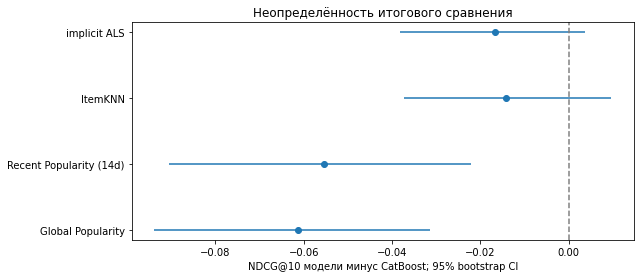

In [7]:
from src.experiment_analysis import paired_metric_comparison
test_intervals = paired_metric_comparison(test_per_user, reference="CatBoostRanker (ALS + ItemKNN)", seed=SEED)
display(test_intervals.round(6))
test_intervals.to_csv(METRICS / "ltr_test_paired_intervals.csv", index=False)
fig, ax = plt.subplots(figsize=(9, 4))
ax.errorbar(test_intervals["delta"], test_intervals["model"], xerr=[test_intervals["delta"]-test_intervals["ci_low"], test_intervals["ci_high"]-test_intervals["delta"]], fmt="o")
ax.axvline(0, color="gray", linestyle="--")
ax.set(xlabel="NDCG@10 модели минус CatBoost; 95% bootstrap CI", title="Неопределённость итогового сравнения")
plt.show()

Отрицательная разница означает преимущество CatBoost; если весь интервал ниже нуля, данные поддерживают этот знак на текущей когорте. Если интервал включает ноль, наблюдаемый прирост не позволяет уверенно установить знак. Это парный bootstrap пользователей с фиксированными обученными моделями, а не проверка устойчивости к seed, временным срезам или зависимости пользователей через общие товары. По этим интервалам параметры повторно не подбираем.

**Результат выполненного прогона.** В направлении CatBoost минус ItemKNN прирост +0.01424 имеет 95% интервал [−0.00956; +0.03727], а CatBoost минус ALS — +0.01675 с интервалом [−0.00374; +0.03822]. Оба включают ноль: заметный относительный прирост среднего пока не доказывает устойчивую победу над коллаборативными моделями. Против обоих popularity baseline интервалы поддерживают преимущество CatBoost. Для более уверенного решения нужны дополнительные заранее заданные временные срезы и seed на development-данных; текущий test не превращаем в площадку следующего подбора.


## Полнота кандидатов

**Гипотеза.** Объединение ALS и ItemKNN найдёт больше будущих целей, чем каждый генератор отдельно. Таблица и график проверяют, ограничен ли ранжировщик уже на первом этапе.

In [8]:
validation_candidate_recall = candidate_recall_at_100(
    validation_candidates, validation, train, cohort, catalog,
    k=CANDIDATES_PER_MODEL,
)
validation_candidate_recall["split"] = "validation"
test_candidate_recall = candidate_recall_at_100(
    test_candidates, test, pretest_history, cohort, catalog,
    k=CANDIDATES_PER_MODEL,
)
test_candidate_recall["split"] = "test"
candidate_recall_results = pd.concat(
    [validation_candidate_recall, test_candidate_recall], ignore_index=True
)
candidate_recall_results.to_csv(METRICS / "ltr_candidate_recall.csv", index=False)
candidate_recall_display = candidate_recall_results.copy()
candidate_recall_display["split"] = candidate_recall_display["split"].map(
    {"validation": "Проверочная выборка", "test": "Тестовая выборка"}
)
candidate_recall_display["generator"] = candidate_recall_display["generator"].replace({
    "implicit ALS": "ALS из implicit",
    "ItemKNN + implicit ALS (up to 200 unique)": "ItemKNN + ALS из implicit (до 200 уникальных)",
})
display(candidate_recall_display.rename(columns={
    "split": "Выборка", "generator": "Генератор кандидатов",
    "candidate_recall@100": "Полнота кандидатов@100", "users": "Число пользователей",
}))

,Генератор кандидатов,Полнота кандидатов@100,Число пользователей,Выборка
0,ALS из implicit,0.239366,242,Проверочная выборка
1,ItemKNN,0.213994,242,Проверочная выборка
2,ItemKNN + ALS из implicit (до 200 уникальных),0.315922,242,Проверочная выборка
3,ALS из implicit,0.217776,148,Тестовая выборка
4,ItemKNN,0.185764,148,Тестовая выборка
5,ItemKNN + ALS из implicit (до 200 уникальных),0.275313,148,Тестовая выборка


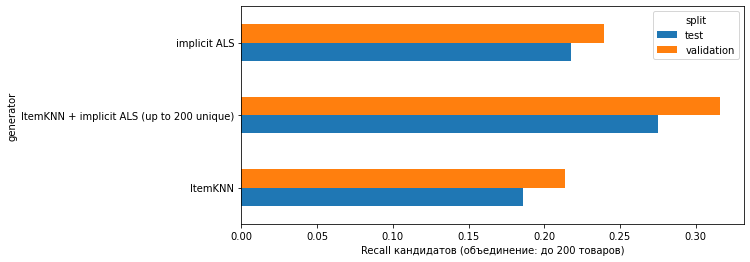

In [9]:
candidate_recall_results.pivot(index="generator", columns="split", values="candidate_recall@100").plot.barh(figsize=(9, 4))
plt.xlabel("Recall кандидатов (объединение: до 200 товаров)")
plt.show()

**Вывод.** В сохранённом прогоне полнота объединения 0.3159 на validation и 0.2753 на test против 0.2394/0.2178 у ALS. Источники дополняют друг друга, хотя объединение использует до 200 позиций против 100 у каждого источника. На test около 72.5% целей в среднем по пользователям отсутствуют среди кандидатов: перестановка их не восстановит. Это потолок Recall для данного набора кандидатов, а не численный потолок NDCG.

## 8. Важность признаков и сравнение моделей

Важность признаков описывает вклад в работу модели, но не доказывает причинно-следственную связь. Она рассчитана для обученного ранжировщика и показана вместе с метриками на проверочной и тестовой выборках, полученными по единому протоколу.

**Гипотеза.** Популярность/активность и сигналы генераторов входят в наиболее используемые признаки. Проверяем важность описательно; доказательством полезности групп служит абляция выше, а не сама важность.

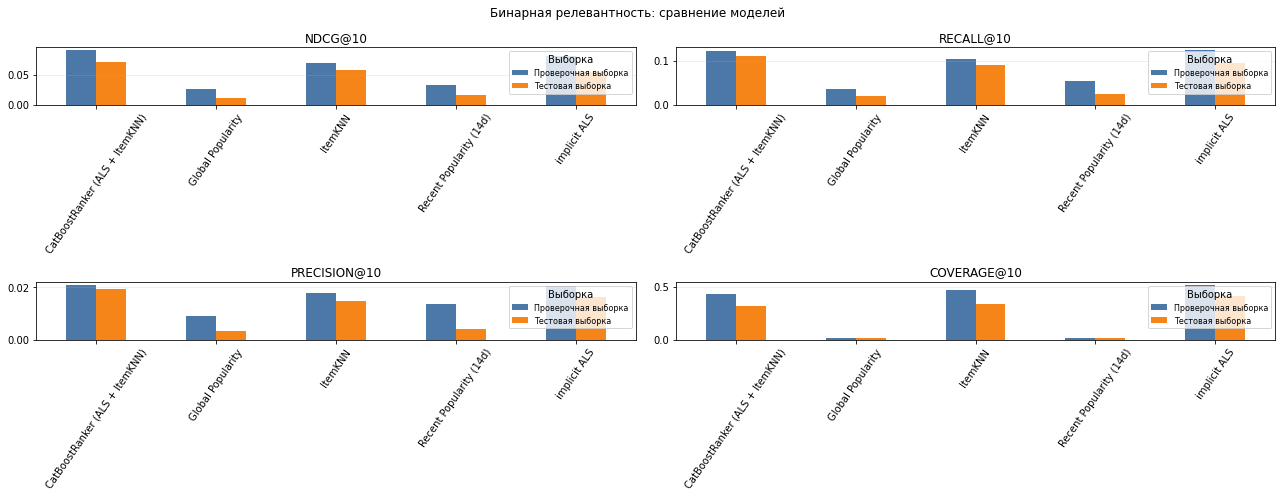

,Признак,Важность
0,Оценка ALS,0.026095
1,Источник кандидата,0.025453
2,События товара за 7 дней,0.017982
3,Ранг ItemKNN,0.017546
4,Ранг ALS,0.017173
5,Оценка ItemKNN,0.008670
6,Добавления товара в корзину,0.005073
7,Просмотры товара,0.004356
8,Уникальные пользователи товара,0.004170
9,Покупки товара,0.003811


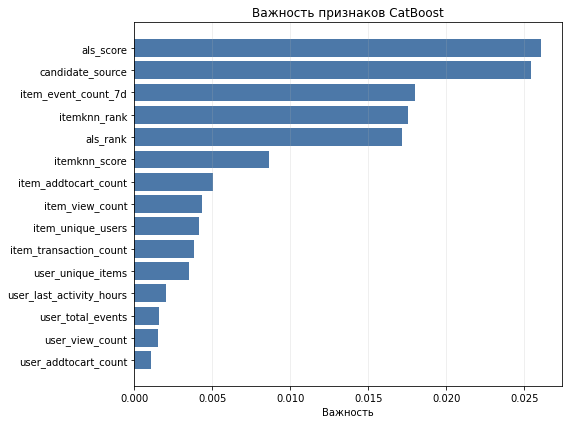

In [10]:
metric_names = ["ndcg@10", "recall@10", "precision@10", "coverage@10"]
comparison = pd.concat(
    {"validation": validation_results, "test": test_results},
    names=["split"],
).reset_index()
comparison["split"] = comparison["split"].map(
    {"validation": "Проверочная выборка", "test": "Тестовая выборка"}
)
fig, axes = plt.subplots(2, 2, figsize=(18, 7))
for axis, metric in zip(axes.flat, metric_names):
    pivot = comparison.pivot(index="model", columns="split", values=metric)
    pivot.plot(kind="bar", ax=axis, color=["#4C78A8", "#F58518"])
    axis.set_title(metric.upper())
    axis.set_xlabel("")
    axis.tick_params(axis="x", labelrotation=55)
    axis.legend(title="Выборка", fontsize=8)
    axis.grid(axis="y", alpha=0.25)
fig.suptitle("Бинарная релевантность: сравнение моделей")
fig.tight_layout()
fig.savefig(FIGURES / "learning_to_rank_metrics.png", dpi=160,
            bbox_inches="tight")
plt.show()

importance_train = rank_training[
    rank_training.groupby(["snapshot_id", "user_id"])["target"].transform("max") > 0
]
importance = feature_importance_frame(ranker, make_ranker_pool(importance_train))
importance.to_csv(METRICS / "ltr_feature_importance.csv", index=False)
importance_display = importance.head(15).copy()
importance_display["feature"] = importance_display["feature"].map(
    lambda feature: FEATURE_LABELS.get(feature, feature)
)
display(importance_display.rename(columns={"feature": "Признак", "importance": "Важность"}))
fig, ax = plt.subplots(figsize=(8, 6))
top_importance = importance.head(15).sort_values("importance")
ax.barh(top_importance["feature"], top_importance["importance"],
        color="#4C78A8")
ax.set(title="Важность признаков CatBoost", xlabel="Важность", ylabel="")
ax.grid(axis="x", alpha=0.25)
fig.tight_layout()
fig.savefig(FIGURES / "ltr_feature_importance.png", dpi=160,
            bbox_inches="tight")
plt.show()

**Вывод по важности признаков.** В выполненном прогоне лидируют `als_score`, `candidate_source` и `item_event_count_7d`, затем ранги ItemKNN и ALS. Это согласуется с совместным использованием коллаборативного сигнала и недавней популярности. Нулевая важность `has_als`/`has_itemknn` не доказывает бесполезность наличия источника: ту же информацию частично несут источник кандидата и ранги. Числа важности не интерпретируем как доли причинного вклада.


## 9. Анализ активности и ошибок

Качество измеряется отдельно в трёх группах пользователей, сформированных только по числу событий в истории до начала тестового периода. Это позволяет увидеть, как персонализация меняется с доступным объёмом истории. В таблице пропущенных целей различаются два случая: товар не был найден генераторами либо попал в набор кандидатов, но не вошёл в топ-10.

**Гипотеза.** Качество зависит от объёма истории; ошибки возникают и при генерации, и при ранжировании. Сравниваем группы описательно, без подбора по test.

Модель,CatBoostRanker (ALS + ItemKNN),Global Popularity,ItemKNN,Recent Popularity (14d),implicit ALS
Группа активности,,,,,
Высокая,0.1266,0.0280,0.0766,0.0207,0.0738
Низкая,0.0365,0.0000,0.0404,0.0000,0.0379
Средняя,0.0584,0.0059,0.0583,0.0294,0.0559


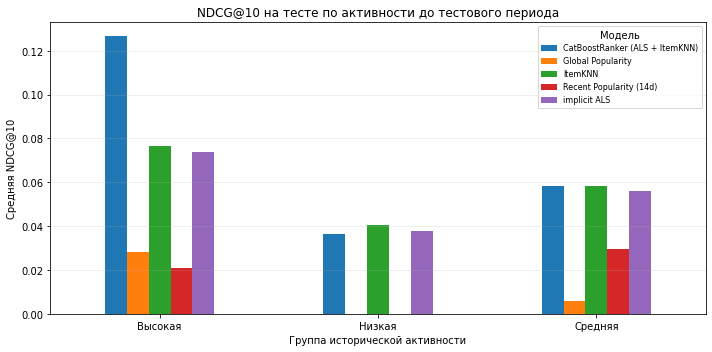

Ненаблюдавшиеся ранее целевые пары, пропущенные CatBoost Top-10: 263


,ID пользователя,ID целевого товара,Будущие события,Кандидат сгенерирован,Источник кандидата,Попал в Top-10 ранжировщика
0,17939,390591,просмотр,False,Не сгенерирован,False
1,28995,190536,просмотр,False,Не сгенерирован,False
2,38102,247909,просмотр,False,Не сгенерирован,False
3,49384,73311,просмотр,False,Не сгенерирован,False
4,61715,68000,просмотр,True,Только ALS,False
5,61715,325852,просмотр,False,Не сгенерирован,False
6,106649,320130,просмотр,True,Только ItemKNN,False
7,108759,19976,просмотр,False,Не сгенерирован,False
8,108759,199838,просмотр,False,Не сгенерирован,False
9,141989,367102,просмотр,False,Не сгенерирован,False


In [11]:
activity = (
    test_features.groupby("user_id", as_index=False)["user_total_events"]
    .first()
)
activity["activity_group"] = pd.qcut(
    activity["user_total_events"].rank(method="first"),
    q=3,
    labels=["Низкая", "Средняя", "Высокая"],
)
activity_rows = []
for model_name, per_user in test_per_user.items():
    joined = per_user.merge(activity, on="user_id", how="left", validate="one_to_one")
    for group_name, group in joined.groupby("activity_group", observed=False):
        activity_rows.append({
            "model": model_name,
            "activity_group": str(group_name),
            "ndcg@10": group["ndcg@10"].mean(),
            "users": len(group),
        })
activity_results = pd.DataFrame(activity_rows)
activity_results.to_csv(METRICS / "ltr_activity_groups.csv", index=False)
display(activity_results.pivot(index="activity_group", columns="model",
                               values="ndcg@10").rename_axis(
                                   index="Группа активности", columns="Модель"
                               ).round(4))
fig, ax = plt.subplots(figsize=(10, 5))
activity_results.pivot(index="activity_group", columns="model",
                       values="ndcg@10").plot(kind="bar", ax=ax)
ax.set(title="NDCG@10 на тесте по активности до тестового периода",
       xlabel="Группа исторической активности", ylabel="Средняя NDCG@10")
ax.tick_params(axis="x", labelrotation=0)
ax.grid(axis="y", alpha=0.25)
ax.legend(title="Модель", fontsize=8)
fig.tight_layout()
fig.savefig(FIGURES / "ltr_activity_groups.png", dpi=160,
            bbox_inches="tight")
plt.show()

history_seen = (
    pretest_history.groupby("visitorid")["itemid"]
    .agg(lambda values: set(int(value) for value in values))
    .to_dict()
)
candidate_sources = test_candidates.set_index(["user_id", "item_id"])
ranker_top10 = test_recommendations["CatBoostRanker (ALS + ItemKNN)"]
target_pairs = test_benchmark.groupby(["visitorid", "itemid"])["event"].agg(
    lambda values: ", ".join(sorted(set(values)))
)
missed_rows = []
for (user_id, item_id), event_types in target_pairs.items():
    event_types = ", ".join({
        "view": "просмотр", "addtocart": "добавление в корзину",
        "transaction": "покупка",
    }.get(event, event) for event in event_types.split(", "))
    user_id, item_id = int(user_id), int(item_id)
    if item_id in history_seen.get(user_id, set()):
        continue
    if item_id in ranker_top10.get(user_id, []):
        continue
    generated = (user_id, item_id) in candidate_sources.index
    source = candidate_sources.loc[(user_id, item_id), "candidate_source"] if generated else "not generated"
    source = {
        "both": "Обе модели", "als_only": "Только ALS",
        "itemknn_only": "Только ItemKNN", "not generated": "Не сгенерирован",
    }[source]
    missed_rows.append({
        "ID пользователя": user_id,
        "ID целевого товара": item_id,
        "Будущие события": event_types,
        "Кандидат сгенерирован": generated,
        "Источник кандидата": source,
        "Попал в Top-10 ранжировщика": False,
    })
missed_targets = pd.DataFrame(missed_rows)
print("Ненаблюдавшиеся ранее целевые пары, пропущенные CatBoost Top-10:", len(missed_targets))
display(missed_targets.head(10))

**Вывод по группам и ошибкам.** NDCG CatBoost растёт с исторической активностью: 0.03650 → 0.05840 → 0.12659. Но в низкой группе ItemKNN лучше (0.04042), в средней почти равен (0.05825), а основной выигрыш ранжировщика сосредоточен в высокой группе (ItemKNN 0.07660). Значит, улучшение среднего не равномерно по аудитории. В группах только 51, 51 и 46 оцениваемых пользователей; разбиение по рангам может разделить одинаковую активность, а различия не доказывают причинный эффект длины истории. Таблица ошибок показывает примеры пропущенных целей, а полнота кандидатов выше даёт количественную оценку потерь первого этапа.


## 10. Выводы и ограничения

Ни одна конфигурация не выбирается по тестовой выборке: параметры ItemKNN и implicit ALS выбраны в ноутбуке 02, CatBoostRanker — по проверочной выборке в этом ноутбуке. Итоговые тестовые метрики, разрыв качества между группами активности, результаты абляций и важность признаков рассчитаны ниже из данных и сохранены в `outputs/metrics/`. Абляции являются диагностикой на проверочной выборке; тест не используется для выбора признаков.

Ранжировщик может переставить только уже сгенерированные товары; недостаточная полнота кандидатов ограничивает его потолок. Бенчмарк охватывает пользователей с историей и каталог из 1 500 товаров, выбранный по обучающей выборке, поэтому не решает холодный старт.

In [12]:
ranker.save_model(str(MODELS / "catboost_ranker.cbm"))
experiment_config = {
    "catboost_version": catboost.__version__,
    "ranker_params": ranker_params,
    "selected_base_params": selected_parameters,
    "catboost_tuning_validation": catboost_tuning.to_dict(orient="records"),
    "feature_ablation_validation": ablation_results.to_dict(orient="records"),
    "selected_catboost_configuration": best_catboost_name,
    "selected_catboost_validation_ndcg@10": float(catboost_tuning.loc[best_catboost_index, "ndcg@10"]),
    "best_iteration": int(best_iteration),
    "early_stopping_rounds": 50,
    "random_seed": SEED,
    "candidate_generators": ["implicit ALS", "ItemKNN"],
    "candidates_per_generator": CANDIDATES_PER_MODEL,
    "rank_training_snapshot_start": str(rank_history.event_time.min()),
    "rank_training_snapshot_cutoff": str(rank_cutoff),
    "rank_training_target_end": str(rank_target.event_time.max()),
    "validation_start": str(validation.event_time.min()),
    "test_start": str(test.event_time.min()),
    "benchmark_users": len(cohort),
    "rank_training_users": len(rank_users),
    "catalog_items": len(catalog),
    "relevance": "binary future user-item interaction",
}
with (MODELS / "catboost_ranker_config.json").open("w") as file:
    json.dump(experiment_config, file, indent=2)

best_validation_name = validation_results["ndcg@10"].idxmax()
print("Лучшая модель по NDCG@10 на проверочной выборке:", best_validation_name)
print("NDCG@10 на тестовой выборке:", test_results["ndcg@10"].to_dict())
print("Таблицы подбора и абляции основаны только на проверочной выборке.")
print("Модель сохранена:", MODELS / "catboost_ranker.cbm")
print("Конфигурация сохранена:", MODELS / "catboost_ranker_config.json")

Лучшая модель по NDCG@10 на проверочной выборке: CatBoostRanker (ALS + ItemKNN)
NDCG@10 на тестовой выборке: {'CatBoostRanker (ALS + ItemKNN)': 0.07204770153555043, 'ItemKNN': 0.05781090921329619, 'implicit ALS': 0.055296365295692394, 'Recent Popularity (14d)': 0.016578266901291723, 'Global Popularity': 0.010739521469681457}
Таблицы подбора и абляции основаны только на проверочной выборке.
Модель сохранена: /Users/mariatreseva/Desktop/ML/ecommerce-recommender-system/outputs/models/catboost_ranker.cbm
Конфигурация сохранена: /Users/mariatreseva/Desktop/ML/ecommerce-recommender-system/outputs/models/catboost_ranker_config.json
